# How large does the outbreak get? The final size and why it ignores time

**Question:** What share of a population does an outbreak infect in the end, why does that share depend on $R_0$ and not on how fast the outbreak runs, and when does the engine's own run fail to reach it?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can solve the final-size relation by iteration and watch it converge, place the removed fractions the engine simulates on the curve of the relation, show that two outbreaks with the same $R_0$ and different speeds end at the same size, and tell how the first infected people and the length of the horizon change the answer.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with the exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This example product publishes no package of its own: its method lives in `data-pipeline/pipeline/`, so the notebook imports that code by its path. A product imports its own PyPI package instead (`pip install <package>==<version>`).

The next cell imports the tools and the pipeline's modules, prints the versions and defines the reader of the cases' parameters.

In [1]:
# the tools, their versions, the pipeline's modules and the reader of the cases' parameters
import importlib.metadata as md
import json
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.io.schema import SIRParams
from pipeline.model.sir import simulate
from pipeline.oracles import final_size

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def params_of(case_id):
    manifest = ROOT / "data" / "derived" / "manifests" / f"{case_id}.json"
    return SIRParams(case_id, **json.loads(manifest.read_text(encoding="utf-8"))["params"])


index = json.loads((ROOT / "data" / "derived" / "manifests" / "index.json").read_text(encoding="utf-8"))
CASES = [c["case_id"] for c in index["cases"]]

numpy 2.4.6
matplotlib 3.11.2


## Data

The parameters of the five cases of the example.

- Owner: this repository (the product template's example), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Licence class: synthetic data produced by the pipeline from the parameters in each manifest (`real_or_synthetic` is `synthetic`); no third-party dataset, so no dataset licence applies, and the repository's MIT licence covers the artifacts.
- Files read: `data/derived/manifests/index.json` and `data/derived/manifests/<case>.json`, for the parameters only; every course shown here is computed by the engine.

## Method

Divide the equation for $S$ by the equation for $R$ in the SIR system: the time cancels and $dS/dR = -(\beta / \gamma) S / N$, which integrates to $S = S_0 \, e^{-R_0 R / N}$. When the outbreak has ended nobody is infected, so $S_\infty = N - R_\infty$ and the share ever infected $z = R_\infty / N$ satisfies

$$1 - z = (1 - i_0)\, e^{-R_0 z}$$

with $i_0 = I_0 / N$ (Kermack and McKendrick, 1927; Miller, 2012). The contact rate and the recovery rate appear only through their ratio and time does not appear at all. For $i_0 \to 0$ and $R_0 \le 1$ the only solution is $z = 0$. The function `final_size` of `data-pipeline/pipeline/oracles.py` solves it by fixed-point iteration: it starts at $z = 1$ and repeats $z \leftarrow 1 - (1 - i_0) e^{-R_0 z}$ until two consecutive values differ by less than $10^{-12}$. It shares no code with the engine, so a disagreement between the two says something about one of them.

First the iteration itself, for the epidemic case, $R_0 = 2.75$. The cell keeps every iterate and prints the first six, the number of iterations and the solution. The iteration starts at the worst guess, everybody infected, so the first iterates come down toward the answer.

In [2]:
# solve the final-size relation for the epidemic case by fixed-point iteration and keep every iterate
r0 = 2.75
iterates = []
z = final_size(r0, trace=iterates)
print("first iterates", [round(float(v), 5) for v in iterates[:6]])
print(f"iterations: {len(iterates)}, z = {z:.6f}")

first iterates [0.93607, 0.92379, 0.92117, 0.9206, 0.92047, 0.92044]
iterations: 18, z = 0.920437


The iterates 0.93607, 0.92379, 0.92117 settle on 0.92044 within six steps, and the loop stops after 18 when the change is below the tolerance. A solution that comes this fast is not guaranteed at every $R_0$: the next cell repeats the iteration for four values, from a barely super-critical 1.2 to a violent 6.0, and counts the iterations each one needs.

In [3]:
# the same iteration for four values of R0, to see how many steps each one needs
traces = {}
for value in (1.2, 1.5, 2.75, 6.0):
    traces[value] = []
    final_size(value, trace=traces[value])
    print(f"R0 = {value:4.2f}  z = {traces[value][-1]:.4f}  {len(traces[value]):4d} iterations")

R0 = 1.20  z = 0.3137   127 iterations
R0 = 1.50  z = 0.5828    55 iterations
R0 = 2.75  z = 0.9204    18 iterations
R0 = 6.00  z = 0.9975     7 iterations


The next cell draws the iterates against the iteration number for the four values of $R_0$.

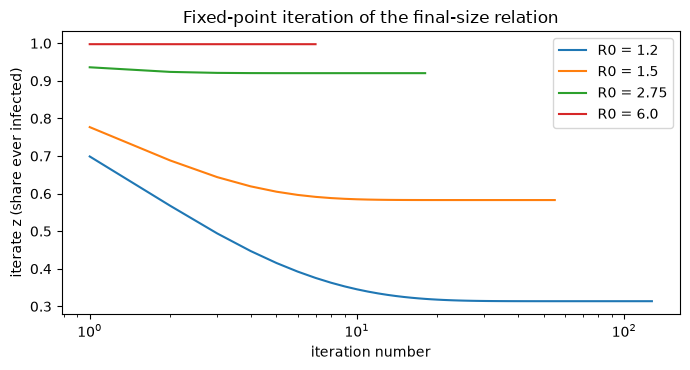

In [4]:
# draw the iterates against the iteration number for the four values of R0
fig, ax = plt.subplots(figsize=(7, 3.8))
for value, trace in traces.items():
    ax.plot(range(1, len(trace) + 1), trace, label=f"R0 = {value}")
ax.set_xscale("log")
ax.set_xlabel("iteration number")
ax.set_ylabel("iterate z (share ever infected)")
ax.set_title("Fixed-point iteration of the final-size relation")
ax.legend()
fig.tight_layout()
plt.show()

Each curve is an iteration, and they all fall from 1 toward their own answer. For $R_0 = 6$ it is over in 7 steps; for $R_0 = 1.2$ it takes 127, because close to the threshold the map $z \mapsto 1 - e^{-R_0 z}$ is almost tangent to the diagonal and the iterates creep. The figure uses a logarithmic axis for the iteration number so that both extremes are visible. It says nothing about the engine yet; the next cell brings it in by computing the relation over a grid of $R_0$ and simulating every case that has infected people.

In [5]:
# Report the horizon cutoff and infinite-time relation as different quantities.
grid = np.linspace(0.5, 6.5, 121)
curve = [final_size(g) for g in grid]
points = {}
for case_id in CASES:
    p = params_of(case_id)
    if p.I0 == 0:
        continue
    run = simulate(p)
    r0_case = p.beta / p.gamma
    limit = final_size(r0_case, p.I0 / p.N)
    removed = run.R[-1] / p.N
    ever = (run.I[-1] + run.R[-1]) / p.N
    points[case_id] = (r0_case, removed)
    additional = run.I[-1] + run.R[-1] - p.I0
    print(f"{case_id}: R(T)/N={removed:.7f}, ever={ever:.7f}, I(T)={run.I[-1]:.3f}")
    print(f"limit={limit:.7f}, removed-minus-limit={removed-limit:+.7f}, additional={additional:.2f}")
    print(f"total infected={ever*p.N:.2f}, initial={p.I0:.0f}")

EX01_subcritical: R(T)/N=0.0017805, ever=0.0017805, I(T)=0.001
limit=0.0017805, removed-minus-limit=+0.0000000, additional=128.05
total infected=178.05, initial=50
EX02_epidemic: R(T)/N=0.9236543, ever=0.9236543, I(T)=0.000
limit=0.9204875, removed-minus-limit=+0.0031668, additional=92315.43
total infected=92365.43, initial=50
EX03_fast_burn: R(T)/N=0.9982142, ever=0.9982142, I(T)=0.000
limit=0.9974861, removed-minus-limit=+0.0007281, additional=99721.42
total infected=99821.42, initial=100
EX04_slow_spread: R(T)/N=0.2992847, ever=0.3021744, I(T)=288.967
limit=0.3156283, removed-minus-limit=-0.0163436, additional=30167.44
total infected=30217.44, initial=50


The next cell draws the curve of the relation and places each case on it at its $R_0$ and its simulated removed fraction.

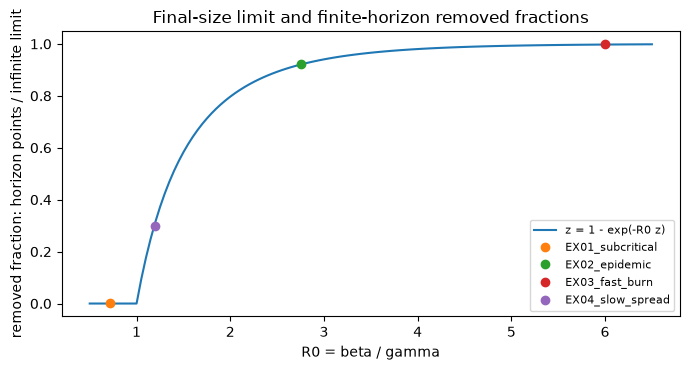

In [6]:
# draw the relation's curve and place each case at its R0 and its simulated removed fraction
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, curve, label="z = 1 - exp(-R0 z)")
for case_id, (r0_case, attack) in points.items():
    ax.plot([r0_case], [attack], "o", label=case_id)
ax.set_xlabel("R0 = beta / gamma")
ax.set_ylabel("removed fraction: horizon points / infinite limit")
ax.set_title("Final-size limit and finite-horizon removed fractions")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The curve is the vanishing-seed limit; the points are finite-case R(T)/N. The subcritical case ends near 0.0017805, about 178 people in total:50 initially infected plus about 128 additional infections, not almost nobody beyond the initial seed. Its residual infected count is negligible at this precision. The epidemic case exceeds its own finite-seed limit by about 0.0032, whereas the fast burn exceeds it by about 0.0007. The slow case falls short because about 289 people remain infected: R(T)/N≈0.2992847 versus [I(T)+R(T)]/N≈0.3021744. Numerical discrepancy and an unfinished horizon are different effects.

Now the claim that time does not matter. The cell runs the epidemic case and a twin whose contact rate and recovery rate are both doubled, so the outbreak runs twice as fast and $R_0$ is still 2.75. If the relation is right, the peak should come about twice as early and the removed fractions should be nearly the same.

In [7]:
# the epidemic case and a twin twice as fast, which has the same R0 = 2.75
base = params_of("EX02_epidemic")
twin = replace(base, beta=2 * base.beta, gamma=2 * base.gamma)
runs = {"EX02_epidemic": simulate(base), "twice as fast": simulate(twin)}
for label, r in runs.items():
    print(f"{label:16s} peak {r.peak_I:7.0f}  on day {r.t_peak:6.2f}  removed fraction {r.attack_rate:.4f}")

EX02_epidemic    peak   27345  on day  24.25  removed fraction 0.9237
twice as fast    peak   27836  on day  12.50  removed fraction 0.9269


The next cell draws the infected people of the two runs on the same axes.

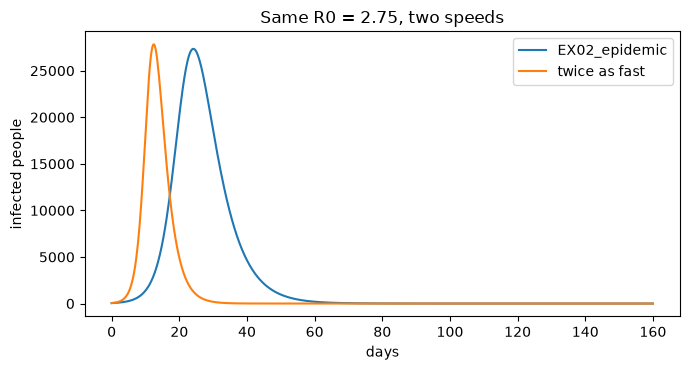

In [8]:
# draw the infected people of the two runs on the same axes
fig, ax = plt.subplots(figsize=(7, 3.8))
for label, r in runs.items():
    ax.plot(r.t, r.I, label=label)
ax.set_xlabel("days")
ax.set_ylabel("infected people")
ax.set_title("Same R0 = 2.75, two speeds")
ax.legend()
fig.tight_layout()
plt.show()

The faster twin peaks on day 12.50 rather than 24.25, approximately compressing the epidemic in time. Its final removed fraction is 0.9269 rather than 0.9237. These finite-step values are close, but are not identical continuous-model limits: the larger Euler error of the faster rates explains the difference. The figure shows that the peak arrives earlier; it does not demonstrate equal areas under the infected curves. In the continuous model, the identity dR/dt = gamma I means that doubling gamma at an unchanged eventual removed count halves the time integral of I. Similar limiting toll and similar infected-person-time are therefore different claims.

The relation has a second argument, the initial infected share $i_0$, that the earlier cells left at zero. The next cell raises the first infected people to 5000 and 20000 and compares three numbers: the relation with $i_0$, the relation without it, and the engine.

In [9]:
# raise the first infected people to 5000 and to 20000: the relation follows the engine when it is given i0
for first in (50, 5000, 20000):
    q = replace(base, I0=first)
    z_i0 = final_size(2.75, first / base.N)
    print(f"I0 = {first:6d}  z(R0, i0) = {z_i0:.4f}  z(R0) = {final_size(2.75):.4f}", end="  ")
    print(f"simulated {simulate(q).attack_rate:.4f}")

I0 =     50  z(R0, i0) = 0.9205  z(R0) = 0.9204  simulated 0.9237
I0 =   5000  z(R0, i0) = 0.9254  z(R0) = 0.9204  simulated 0.9287
I0 =  20000  z(R0, i0) = 0.9396  z(R0) = 0.9204  simulated 0.9428


With 20000 people infected at the start, one fifth of the town, the relation without $i_0$ is wrong by 0.019, while the relation with $i_0$ stays within 0.0033 of the engine in all three rows. Those case-specific gaps reflect Euler discretization, and it says the relation, with its second argument, describes what the engine does. The last case is the slow spread, whose removed fraction stopped short of the relation. The cell runs it at its own 160-day horizon and at 300 days.

In [10]:
# the slow-spread case at its 160-day horizon and at 300 days, against the relation
slow = params_of("EX04_slow_spread")
z_slow = final_size(slow.beta / slow.gamma, slow.I0 / slow.N)
for horizon in (160, 300):
    r = simulate(replace(slow, days=horizon))
    print(f"horizon = {horizon:3d}  removed fraction {r.attack_rate:.4f}  z = {z_slow:.4f}")

horizon = 160  removed fraction 0.2993  z = 0.3156
horizon = 300  removed fraction 0.3162  z = 0.3156


### Sensitivity: a small iterate change is not always a small solution error

Write the map implemented by the oracle as $F(z)=1-(1-i_0)\exp(-R_0z)$. At a converged solution $z^*$ its local contraction factor is

$$F'(z^*)=R_0(1-i_0)e^{-R_0z^*}=R_0(1-z^*).$$

The derivative is dimensionless because both input and output are fractions. When its magnitude is well below one, each remaining error shrinks rapidly. Close to the threshold it approaches one and adjacent iterates can differ little while the distance to the solution remains appreciable. The oracle stops on successive-iterate difference and returns its current value if its iteration budget expires; it does not return a convergence-status object. A caller needing a certificate must examine the fixed-point residual and sensitivity to a larger budget rather than treating every float as a certified answer.

There is also a branch issue. For exactly zero initial infections the deterministic time-dependent system stays disease free. Calling this oracle with `i0=0` and reproduction ratio above one instead selects the nonzero outbreak branch by starting at one; epidemiologically that is the limiting final size conditional on a small positive seed, not an outbreak generated from an exactly uninfected town. The notebook omits the unseeded control when placing engine runs on this curve for that reason. A small finite seed and an exactly absent seed answer different questions.

Initial immunity is absent from this oracle's signature. Its susceptible initial share is assumed to be one minus the infected share, with zero recovered initially. If immunity is present, transform the reduced nonimmune population and the effective rate consistently, as in the preceding threshold lesson, or use a model whose documented oracle includes the extra initial condition. Merely inserting the original reproduction ratio into this relation would retain the wrong susceptible population.

In [11]:
# Compare finite iteration budgets near the threshold without redefining the oracle.
for budget in (10, 100, 10000):
    candidate = final_size(1.001, tolerance=1e-12, max_iterations=budget)
    residual = abs(candidate - (1 - np.exp(-1.001 * candidate)))
    print(f"budget={budget:5d}, z={candidate:.8f}, residual={residual:.3e}")

budget=   10, z=0.15907786, residual=1.187e-02
budget=  100, z=0.02034939, residual=1.857e-04
budget=10000, z=0.00199743, residual=9.041e-11


### Use it on your own data

Read one accepted `SIRParams` record, compute `r0=beta/gamma` and `i0=I0/N`, and call `final_size(r0, i0, tolerance=..., max_iterations=...)`. Both arguments are dimensionless; passing an infected count instead of a fraction changes the equation. Request `trace=[]` when diagnosing slow convergence, but avoid storing huge traces unnecessarily. The engine call `simulate(params, dt=...)` remains separate because the oracle supplies no peak day, trajectory or finite-horizon prediction.

Before interpreting a disagreement, inspect the engine's terminal infected fraction and repeat with a longer horizon at a stable step. If infections remain, `R(T)/N` excludes people still infected at time T and is not yet the eventual removed fraction. Then refine the step to distinguish horizon truncation from numerical overshoot. The relation is exact only within the closed homogeneous equations and their stated initial conditions. It does not account for migration, new susceptibility, changing contact rates or observation error. Extending the product to those mechanisms requires a different governing model, not a smaller iteration tolerance. The reported sensitivity is numerical and conditional, with no statistical interval attached.

## Results

**Answer:** For R0=2.75 and I0=50 in 100000 people, the finite-seed final-size limit is 0.9205. The engine returns R(160)/N=0.9237, about 0.0032 higher because of discretization; I(160) is negligible for this completed case. That discrepancy is not universal: the fast burn differs by about 0.0007 and the subcritical discrepancy is much smaller. The subcritical case reaches about 178 total infections, roughly 128 beyond its initial 50.

For the slow case R(160)/N=0.2992847 and [I(160)+R(160)]/N=0.3021744: about 289 people remain infected, so those quantities differ. Its finite-seed limit is about 0.3156, while the 300-day removed fraction reaches 0.3162. Horizon truncation and Euler error must be examined separately. Speeding up both rates preserves the continuous limit for the same initial state but changes peak timing and fixed-step error. The relation supplies no date and does not justify interpreting every legacy `attack_rate` output as cumulative infection at the cutoff.

## Summary

- The final-size relation describes the limiting removed fraction, equal to total infection only as I tends to zero.
- Finite initial state and branch selection matter; an exactly absent seed is different from a small positive seed.
- Euler discrepancy depends on the case and rates, not a universal 0.003 excess.
- The slow case retains infected people at day 160, so R(T)/N omits some infections by T.
- Iteration-budget and horizon limitations require different diagnostics.

## References

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Miller, J. C. (2012). A note on the derivation of epidemic final sizes. Bulletin of Mathematical Biology. https://doi.org/10.1007/s11538-012-9749-6
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- The engine and the oracle of this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`, `pipeline/oracles.py`).